# 01. Formal Exploratory Data Analysis

Structured deep-dive into the dataset. Builds on the preliminary EDA with richer diagnostics.

## 0. Setup & Imports

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120
%matplotlib inline

## 1. Data Loading

Loads the events CSV from `data/raw/`.

In [2]:
raw_dir = Path.cwd().parent.parent / "data" / "raw"
raw_dir.mkdir(parents=True, exist_ok=True)

csv_files = list(raw_dir.glob("*.csv"))
if not csv_files:
    raise FileNotFoundError(f"No CSV files found in {raw_dir}. Place a CSV file there and rerun.")

file_path = csv_files[1]
print(f"Loading: {file_path.name}")
df = pd.read_csv(file_path, encoding="utf-8", low_memory=False)

print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]:,} columns")

Loading: events-1681209680.csv


Shape: 124,969 rows x 30 columns


## 2. Initial Inspection

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 124969 entries, 0 to 124968
Data columns (total 30 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   id                      124969 non-null  int64
 1   action                  62481 non-null   str  
 2   action_classification   52950 non-null   str  
 3   action_level            2456 non-null    str  
 4   action_summary          29105 non-null   str  
 5   authorities_link        124887 non-null  str  
 6   country                 124968 non-null  str  
 7   create_date             5201 non-null    str  
 8   data_notes              57928 non-null   str  
 9   date                    48763 non-null   str  
 10  date_initiated_by_firm  55658 non-null   str  
 11  date_posted             44187 non-null   str  
 12  date_terminated         31487 non-null   str  
 13  date_updated            231 non-null     str  
 14  determined_cause        35818 non-null   str  
 15  documents  

In [4]:
df.head(10)

,id,action,action_classification,action_level,action_summary,authorities_link,country,create_date,data_notes,date,...,status,target_audience,type,uid,uid_hash,url,slug,device_id,created_at,updated_at
0,1,NaN,NaN,NaN,Recall,https://www.titck.gov.tr/,TUR,NaN,NaN,2016-04-04,...,NaN,NaN,Field Safety Notice,2016/294 & FA24MAR2016,41570514,https://web.archive.org/web/20170817053524/htt...,tur-cell-dyn-emerald-cleanser,1,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
1,2,NaN,NaN,NaN,Recall,https://www.titck.gov.tr/,TUR,NaN,NaN,2016-09-20,...,NaN,NaN,Field Safety Notice,2016/844 & FSCA2016-02,415f04f4,https://web.archive.org/web/20170817104322/htt...,tur-tecnis-monofocal-1-piece-tecnis-1-piece-io...,2,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
2,3,NaN,NaN,NaN,Recall,https://www.titck.gov.tr/,TUR,NaN,NaN,2016-05-09,...,NaN,NaN,Field Safety Notice,2016/437 & 2016018,2caa03df,https://web.archive.org/web/20170818050616/htt...,tur-centurion-fms-package-for-centurion-vision...,3,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
3,4,NaN,NaN,NaN,Recall,https://www.titck.gov.tr/,TUR,NaN,NaN,2016-12-19,...,NaN,NaN,Field Safety Notice,2016/1188 & 002/AS60130/17.00,666f0625,https://web.archive.org/web/20171014025042/htt...,tur-focusforce-intraocular-foldable-lenses,4,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
4,5,NaN,NaN,NaN,Recall,https://www.titck.gov.tr/,TUR,NaN,NaN,2017-02-20,...,NaN,NaN,Field Safety Notice,2017/242 & 02R06-21 / 02R06-31,6a8d063c,https://web.archive.org/web/20171014000531/htt...,tur-cholesterol-hdl-direct,5,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
5,6,NaN,NaN,NaN,Recall,https://www.titck.gov.tr/,TUR,NaN,NaN,2016-02-08,...,NaN,NaN,Field Safety Notice,2016/117 & Afc-fsca-2015-001,6d9c06ff,https://web.archive.org/web/20170817123339/htt...,tur-blood-glucose-test-strip,6,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
6,7,NaN,NaN,NaN,Recall,https://www.titck.gov.tr/,TUR,NaN,NaN,2016-02-26,...,NaN,NaN,Field Safety Notice,2016/70 & EIF1507-34,291a03fb,https://web.archive.org/web/20170817132536/htt...,tur-super-arrow-flex-r-percutaneous-sheath-int...,7,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
7,8,NaN,NaN,NaN,Recall,https://www.titck.gov.tr/,TUR,NaN,NaN,2016-08-16,...,NaN,NaN,Field Safety Notice,2016/156 & EIF1507-33,3b7804af,https://web.archive.org/web/20170815184818/htt...,tur-catheter-introducer,8,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
8,9,NaN,NaN,NaN,Recall,https://www.titck.gov.tr/,TUR,NaN,NaN,2016-04-28,...,NaN,NaN,Field Safety Notice,2016/156 & EIF1507-33,3b7804af,https://web.archive.org/web/20170815184818/htt...,tur-catheter-introducer-3b7804af,8,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
9,10,NaN,NaN,NaN,Recall,https://www.titck.gov.tr/,TUR,NaN,NaN,2016-02-09,...,NaN,NaN,Field Safety Notice,2016/124 & ASPENR1,2ee10470,https://web.archive.org/web/20170817112452/htt...,tur-22g-bi-manual-aspiration-pull-handle-0-38m...,9,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC


## 3. Column Overview

Data types, non-null counts, cardinality, and memory usage.

In [5]:
schema = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "null_pct": (df.isna().mean() * 100).round(2),
    "cardinality": df.nunique(dropna=False),
    "memory_kb": (df.memory_usage(deep=True) / 1024).round(1)
})
display(schema)
print(f"Total memory: {schema['memory_kb'].sum():,.1f} KB")

,dtype,non_null,null_pct,cardinality,memory_kb
Index,NaN,NaN,NaN,NaN,0.1
action,str,62481.0,50.00,32251.0,31826.8
action_classification,str,52950.0,57.63,12.0,5087.1
action_level,str,2456.0,98.03,7.0,4010.6
action_summary,str,29105.0,76.71,17593.0,6721.9
authorities_link,str,124887.0,0.07,13599.0,10410.9
country,str,124968.0,0.00,47.0,6346.1
create_date,str,5201.0,95.84,629.0,4042.4
created_at,str,124969.0,0.00,8637.0,8786.9
data_notes,str,57928.0,53.65,13277.0,9756.6


Total memory: 334,584.5 KB


In [6]:
dtype_counts = df.dtypes.value_counts()
print("Column type distribution:")
for dtype, count in dtype_counts.items():
    print(f"  {dtype.name}: {count} columns")

Column type distribution:
  str: 28 columns
  int64: 2 columns


In [7]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()

print(f"Numerical columns ({len(num_cols)}): {num_cols}")
print(f"Categorical / text columns ({len(cat_cols)}): {cat_cols}")

Numerical columns (2): ['id', 'device_id']
Categorical / text columns (28): ['action', 'action_classification', 'action_level', 'action_summary', 'authorities_link', 'country', 'create_date', 'data_notes', 'date', 'date_initiated_by_firm', 'date_posted', 'date_terminated', 'date_updated', 'determined_cause', 'documents', 'icij_notes', 'number', 'reason', 'source', 'status', 'target_audience', 'type', 'uid', 'uid_hash', 'url', 'slug', 'created_at', 'updated_at']


## 4. Missing Values Analysis

In [8]:
missing_cols = pd.DataFrame({
    "Missing": df.isna().sum(),
    "%": (df.isna().sum() / len(df) * 100).round(2)
}).sort_values("Missing", ascending=False)

missing_cols = missing_cols[missing_cols["Missing"] > 0]
if missing_cols.empty:
    print("No missing values found.")
else:
    display(missing_cols)
    print(f"\nTotal missing values: {df.isna().sum().sum():,}")

,Missing,%
date_updated,124738,99.82
target_audience,124529,99.65
action_level,122513,98.03
create_date,119768,95.84
action_summary,95864,76.71
date_terminated,93482,74.80
determined_cause,89151,71.34
status,88440,70.77
documents,83930,67.16
number,80958,64.78



Total missing values: 1,576,689


In [9]:
nulls_per_row = df.isna().sum(axis=1)

print("Rows with nulls:")
for threshold in [1, 2, 5, 10, 20, 50]:
    count = (nulls_per_row >= threshold).sum()
    print(f"  >= {threshold:>3} nulls: {count:>6,} rows ({count / len(df) * 100:>5.1f}%)")

print(f"\nNulls per row - distribution:")
dist = nulls_per_row.value_counts().sort_index()
display(dist.head(20).to_frame("# rows"))

Rows with nulls:
  >=   1 nulls: 124,969 rows (100.0%)
  >=   2 nulls: 124,969 rows (100.0%)
  >=   5 nulls: 124,969 rows (100.0%)
  >=  10 nulls: 89,152 rows ( 71.3%)
  >=  20 nulls:      4 rows (  0.0%)
  >=  50 nulls:      0 rows (  0.0%)

Nulls per row - distribution:


,# rows
7,29805
8,5917
9,95
10,93
11,2588
12,7468
13,6192
14,18277
15,26444
16,17816


In [10]:
null_pct = df.isna().mean() * 100
rec_df = pd.DataFrame({
    "Null %": null_pct.round(2),
    "Recommendation": null_pct.apply(
        lambda p: "DROP (>40%)" if p > 40 else "KEEP"
    )
}).sort_values("Null %", ascending=False)

to_drop = rec_df[rec_df["Recommendation"] == "DROP (>40%)"]
if not to_drop.empty:
    print("=" * 55)
    print(f"  {len(to_drop)} column(s) with >40% nulls - recommended for removal")
    print("=" * 55)
    display(to_drop)
else:
    print("No columns exceed 40% nulls - none recommended for removal.")

  17 column(s) with >40% nulls - recommended for removal


,Null %,Recommendation
date_updated,99.82,DROP (>40%)
target_audience,99.65,DROP (>40%)
action_level,98.03,DROP (>40%)
create_date,95.84,DROP (>40%)
action_summary,76.71,DROP (>40%)
date_terminated,74.80,DROP (>40%)
determined_cause,71.34,DROP (>40%)
status,70.77,DROP (>40%)
documents,67.16,DROP (>40%)
number,64.78,DROP (>40%)


## 5. Column Drop Decisions

Columns dropped and their justifications:

| Column | Null % | Reason |
|--------|--------|--------|
| `url` | 19.78 | HTTP 302 redirects, no usable data |
| `updated_at` | 0.00 | Identical to `created_at` (100% match) |
| `target_audience` | 99.65 | Nearly all null |
| `authorities_link` | 0.07 | Not useful for analysis |
| `data_notes` | 53.65 | Over half null |
| `date_posted` | 64.64 | Mostly null |
| `date_terminated` | 74.80 | Mostly null |
| `status` | 70.77 | Mostly null |
| `date_updated` | 99.82 | Nearly all null |
| `action_level` | 98.03 | Nearly all null |
| `create_date` | 95.84 | Nearly all null |

In [11]:
# Verify created_at and updated_at are identical
match_pct = (df['created_at'] == df['updated_at']).sum() / len(df)
print(f"created_at == updated_at: {match_pct:.0%} match")

created_at == updated_at: 100% match


In [12]:
columns_to_drop = [
    'url',            # HTTP 302 redirects, no usable data
    'updated_at',     # Identical to created_at
    'target_audience',# 99.65% null
    'authorities_link',# Not useful for analysis
    'data_notes',     # 53.65% null
    'date_posted',    # 64.64% null
    'date_terminated',# 74.80% null
    'status',         # 70.77% null
    'date_updated',   # 99.82% null
    'action_level',   # 98.03% null
    'create_date',    # 95.84% null
]
df_clean = df.drop(columns=columns_to_drop)
print(f"Shape after dropping {len(columns_to_drop)} columns: {df_clean.shape[0]:,} rows x {df_clean.shape[1]:,} columns")

Shape after dropping 11 columns: 124,969 rows x 19 columns


## 6. Row Filtering

Keep rows with at least 15 non-null values out of 19 remaining columns.

In [13]:
df_clean = df_clean.dropna(thresh=15)
print(f"Shape after dropping rows with <15 non-null values: {df_clean.shape[0]:,} rows x {df_clean.shape[1]:,} columns")

Shape after dropping rows with <15 non-null values: 39,520 rows x 19 columns


In [14]:
# Check date column null rate after filtering
date_nulls = df_clean['date'].isna().sum()
print(f"date column: {date_nulls:,} nulls out of {len(df_clean):,} rows ({date_nulls/len(df_clean)*100:.1f}% null)")

date column: 39,373 nulls out of 39,520 rows (99.6% null)


The `date` column has 99.6% nulls even after row filtering. Dropping it.

In [15]:
df_clean = df_clean.drop(columns=['date'])
print(f"Shape after dropping date: {df_clean.shape[0]:,} rows x {df_clean.shape[1]:,} columns")

Shape after dropping date: 39,520 rows x 18 columns


## 7. Second Dataset & Merge

Load the devices dataset and merge with the events data.

In [16]:
proc_dir = Path.cwd().parent.parent / "data" / "processed"
proc_dir.mkdir(parents=True, exist_ok=True)

csv_files2 = list(proc_dir.glob("*.csv"))
if not csv_files2:
    raise FileNotFoundError(f"No CSV files found in {proc_dir}.")

file_path2 = csv_files2[0]
print(f"Loading: {file_path2.name}")
df_devices = pd.read_csv(file_path2, encoding="utf-8", low_memory=False)
print(f"Shape: {df_devices.shape[0]:,} rows x {df_devices.shape[1]:,} columns")

Loading: devicesProcessed.csv


Shape: 30,556 rows x 12 columns


In [17]:
merged_df = df_clean.merge(df_devices, left_on='device_id', right_on='id', how='inner')
print(f"Merged shape: {merged_df.shape[0]:,} rows x {merged_df.shape[1]:,} columns")

Merged shape: 32,224 rows x 30 columns


In [18]:
merged_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32224 entries, 0 to 32223
Data columns (total 30 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   id_x                    32224 non-null  int64
 1   action                  31952 non-null  str  
 2   action_classification   32224 non-null  str  
 3   action_summary          0 non-null      str  
 4   country                 32224 non-null  str  
 5   date_initiated_by_firm  31423 non-null  str  
 6   determined_cause        32223 non-null  str  
 7   documents               0 non-null      str  
 8   icij_notes              32224 non-null  str  
 9   number                  32224 non-null  str  
 10  reason                  32216 non-null  str  
 11  source                  32224 non-null  str  
 12  type                    32224 non-null  str  
 13  uid                     32224 non-null  str  
 14  uid_hash                32224 non-null  str  
 15  slug_x                  32224 

## 8. Post-Merge Analysis

In [19]:
num_cols = merged_df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = merged_df.select_dtypes(exclude=[np.number]).columns.tolist()

print(f"Numerical columns ({len(num_cols)}): {num_cols}")
print(f"Categorical / text columns ({len(cat_cols)}): {cat_cols}")

Numerical columns (4): ['id_x', 'device_id', 'id_y', 'manufacturer_id']
Categorical / text columns (26): ['action', 'action_classification', 'action_summary', 'country', 'date_initiated_by_firm', 'determined_cause', 'documents', 'icij_notes', 'number', 'reason', 'source', 'type', 'uid', 'uid_hash', 'slug_x', 'created_at_x', 'classification', 'code', 'description', 'distributed_to', 'implanted', 'name', 'quantity_in_commerce', 'risk_class', 'slug_y', 'created_at_y']


The only numerical columns are IDs and foreign keys - not meaningful for statistical analysis.

In [20]:
for col in cat_cols[:10]:
    vc = merged_df[col].value_counts(dropna=False).head(15)
    print(f"\n--- {col} ({vc.sum():,} non-null / {merged_df[col].nunique():,} unique) ---")
    print(vc.to_string())


--- action (2,310 non-null / 13,581 unique) ---
action
NaN                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                             

## 9. Correlation Analysis

Since the only numerical columns are IDs, the correlation matrix is not very informative.

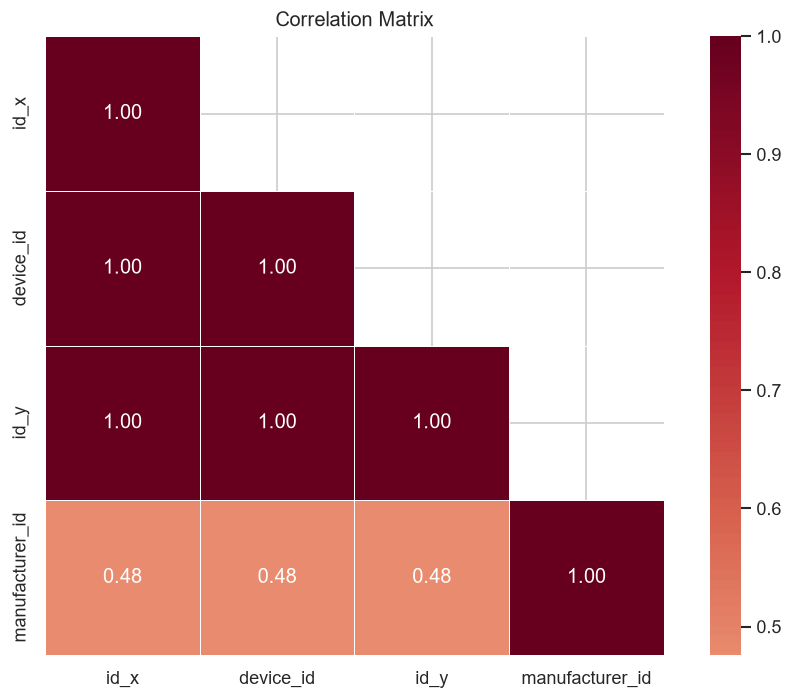

Top 10 strongest correlations:
  id_y  -  device_id: +1.0000
  id_x  -  device_id: +1.0000
  id_y  -  manufacturer_id: +0.4761
  id_x  -  manufacturer_id: +0.4760


In [21]:
if len(num_cols) >= 2:
    corr = merged_df[num_cols].corr()
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    plt.figure(figsize=(max(8, len(num_cols) * 0.6), max(6, len(num_cols) * 0.5)))
    sns.heatmap(corr, mask=mask, annot=len(num_cols) <= 20,
                fmt=".2f", cmap="RdBu_r", center=0,
                square=True, linewidths=0.5)
    plt.title("Correlation Matrix")
    plt.tight_layout()
    plt.show()

    corr_unstacked = corr.unstack()
    corr_unstacked = corr_unstacked[
        corr_unstacked.index.get_level_values(0) !=
        corr_unstacked.index.get_level_values(1)
    ]
    top_corr = corr_unstacked.abs().sort_values(ascending=False).drop_duplicates().head(10)
    print("Top 10 strongest correlations:")
    for (col1, col2), val in top_corr.items():
        print(f"  {col1}  -  {col2}: {corr.loc[col1, col2]:+.4f}")

## 10. Summary

In [22]:
print("=" * 60)
print("EDA SUMMARY")
print("=" * 60)

print(f"\nDataset: {file_path.name}")
print(f"Dimensions: {df.shape[0]:,} rows x {df.shape[1]:,} columns")
print(f"Missing cells: {df.isna().sum().sum():,} / {df.size:,} ({df.isna().sum().sum() / df.size * 100:.2f}%)")
print(f"Rows with >= 1 null: {(df.isna().sum(axis=1) >= 1).sum():,}")
print(f"Columns with >40% nulls: {(df.isna().mean() * 100 > 40).sum()}")
print(f"Duplicate rows: {df.duplicated().sum():,}")
print(f"\nAfter cleaning:")
print(f"  Rows: {df_clean.shape[0]:,}  |  Columns: {df_clean.shape[1]}")
print(f"\nAfter merge with devices:")
print(f"  Rows: {merged_df.shape[0]:,}  |  Columns: {merged_df.shape[1]}")
print(f"  Numerical: {len(num_cols)}  |  Categorical: {len(cat_cols)}")
print(f"  Memory: {merged_df.memory_usage(deep=True).sum() / 1024 ** 2:.2f} MB")

EDA SUMMARY

Dataset: events-1681209680.csv
Dimensions: 124,969 rows x 30 columns
Missing cells: 1,576,689 / 3,749,070 (42.06%)


Rows with >= 1 null: 124,969
Columns with >40% nulls: 17


Duplicate rows: 0

After cleaning:
  Rows: 39,520  |  Columns: 18

After merge with devices:
  Rows: 32,224  |  Columns: 30
  Numerical: 4  |  Categorical: 26
  Memory: 97.84 MB


In [31]:
pathtosave = Path(f'{proc_dir}/mergedDevicesEvents.csv')

In [32]:
merged_df.to_csv(pathtosave);